# Recuperación durable: ventana de fallo y atomicidad
## Pregunta
¿Un checkpoint separado del efecto evita duplicados si el proceso cae después de confirmar el efecto? Se comparan tres implementaciones existentes: reinicio ingenuo, checkpoint separado y transacción atómica con clave idempotente.

Todos los efectos son locales a la misma SQLite. No se afirma exactly-once sobre APIs remotas. Se inyectan excepciones deterministas tras un commit: esto comprueba la ventana lógica, no una pérdida real de energía.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
SEED=20261018


## Diseño del experimento
Cada trabajo tiene dos pasos, reserve y finalize. En modo split, el efecto se confirma antes del checkpoint: una caída en ese intervalo repite el efecto. En modo atomic, ambos se confirman juntos y el índice (job_id,step) es único.

Se varía fracción de trabajos afectados y punto de caída. Cada caso usa una base nueva en un directorio temporal, por lo que reruns no mezclan historial. Se cuentan efectos, trabajos terminados y payloads incorrectos.

In [2]:
from src.engine import initialize,run_job,inspect,InjectedCrash
from tempfile import TemporaryDirectory
rows=[];jobs=30
for fraction in [0.,.25,.5,1.]:
    for crash_step in [0,1]:
        for mode in ['naive','split','atomic']:
            with TemporaryDirectory() as directory:
                database=Path(directory)/'state.sqlite';initialize(database,mode)
                crash_jobs=int(jobs*fraction)
                for job in range(jobs):
                    try:run_job(database,mode,str(job),crash_step if job<crash_jobs else None)
                    except InjectedCrash:pass
                    run_job(database,mode,str(job))
                stats=inspect(database)
                assert stats['completed']==jobs and stats['unique_effects']==2*jobs and stats['bad_payloads']==0
                if mode=='atomic':assert stats['duplicate_effects']==0
                rows.append(dict(fraction=fraction,crash_step=crash_step,mode=mode,**stats))
recovery_table=pd.DataFrame(rows);display(recovery_table)


,fraction,crash_step,mode,jobs,completed,effect_rows,unique_effects,duplicate_effects,bad_payloads
0,0.00,0,naive,30,30,60,60,0,0
1,0.00,0,split,30,30,60,60,0,0
2,0.00,0,atomic,30,30,60,60,0,0
3,0.00,1,naive,30,30,60,60,0,0
4,0.00,1,split,30,30,60,60,0,0
5,0.00,1,atomic,30,30,60,60,0,0
6,0.25,0,naive,30,30,67,60,7,0
7,0.25,0,split,30,30,67,60,7,0
8,0.25,0,atomic,30,30,60,60,0,0
9,0.25,1,naive,30,30,74,60,14,0


## Fracción de fallos no es tasa de fallos de producción
El eje se fija para exponer un mecanismo de recuperación. No estima fiabilidad de una infraestructura real. La posición del fallo cambia cuántos efectos ingenuos se repiten: los dos pasos completos frente al último paso pendiente.

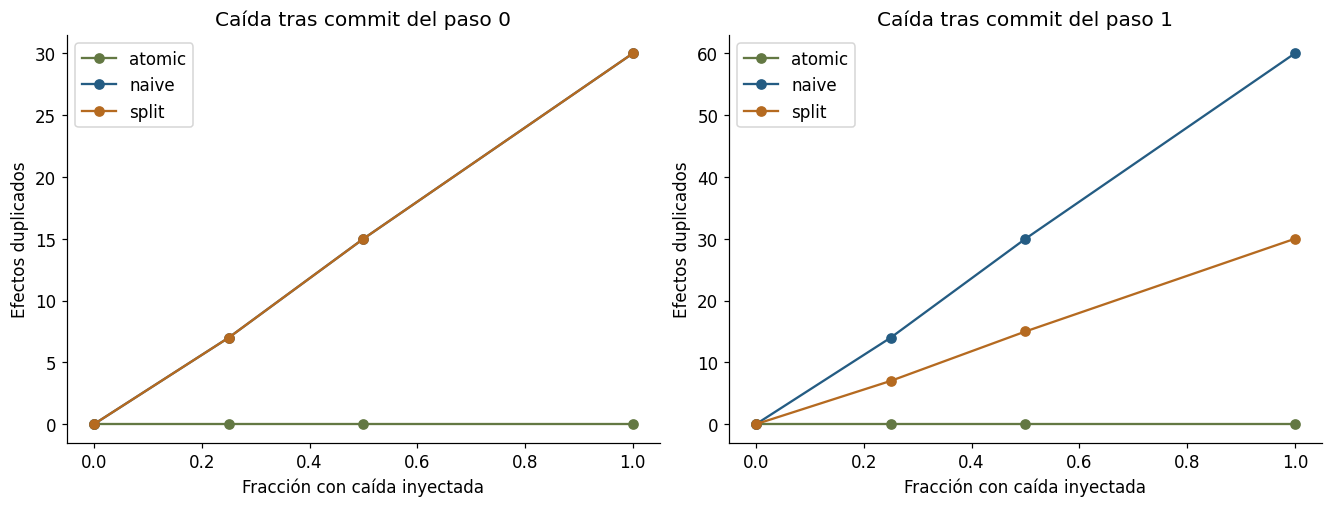

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
colors={'naive':'#245C83','split':'#B56A20','atomic':'#637843'}
for step,ax in enumerate(axes):
    for mode,group in recovery_table[recovery_table.crash_step==step].groupby('mode'):
        ax.plot(group.fraction,group.duplicate_effects,'o-',color=colors[mode],label=mode)
    ax.set(xlabel='Fracción con caída inyectada',ylabel='Efectos duplicados',title=f'Caída tras commit del paso {step}')
    ax.legend()
plt.show()

## Rerun de un trabajo terminado
Se verifica idempotencia de reintento después de completar el trabajo, además de recuperación durante ejecución. La propiedad requiere preservar la identidad del trabajo; cambiar job_id significa crear otro trabajo legítimo.

In [4]:
with TemporaryDirectory() as directory:
    database=Path(directory)/'state.sqlite';initialize(database,'atomic')
    run_job(database,'atomic','same-job');before=inspect(database)
    for _ in range(20):run_job(database,'atomic','same-job')
    after=inspect(database)
    assert before==after
    run_job(database,'atomic','new-job');new=inspect(database)
    assert new['unique_effects']==4 and new['completed']==2
    display(pd.DataFrame([dict(moment='Antes',**before),dict(moment='20 reintentos',**after),dict(moment='Nueva identidad',**new)]))

,moment,jobs,completed,effect_rows,unique_effects,duplicate_effects,bad_payloads
0,Antes,1,1,2,2,0,0
1,20 reintentos,1,1,2,2,0,0
2,Nueva identidad,2,2,4,4,0,0


## Control negativo: efecto externo
Si se confirma un efecto en un sistema externo y el proceso muere antes de guardar checkpoint local, una transacción SQLite no puede revertir ese efecto. La reparación exige idempotency keys en el receptor o un protocolo transaccional apropiado; no basta con declarar una política de retry.

In [5]:
external_effects=[];local_checkpoint=False
external_effects.append('charge')  # Receiver committed before local crash.
if not local_checkpoint:
    external_effects.append('charge')  # Retry has no receiver idempotency key.
    local_checkpoint=True
assert external_effects.count('charge')==2
print('Control negativo conceptual, sin red: efectos externos repetidos =',len(external_effects))

Control negativo conceptual, sin red: efectos externos repetidos = 2


## Límites
No se validaron cortes de energía, corrupción de disco, durabilidad de un proveedor remoto, concurrencia multiproceso ni fencing de workers. El alcance probado es una máquina de dos pasos con efecto y checkpoint en una misma SQLite, conexiones cerradas entre reintentos e identidad estable. Los tests existentes cubren escenarios adicionales y se ejecutan junto con esta ampliación.